In [1]:
import sys 
import pandas as pd

In [2]:
import pyBigWig
import pybedtools 

print("pyBigWig version:", pyBigWig.__version__) 
print("pybedtools version:", pybedtools.__version__)

pyBigWig version: 0.3.24
pybedtools version: 0.12.1


In [3]:
# BED file for TP53 binding peaks 
import pybedtools 
peaks = pybedtools.BedTool("GSE176658_ENCFF041VRQ_IDR_ranked_peaks_GRCh38.bed")

print(peaks.head())
print("Total peaks:" , len(peaks))

chr1	181134909	181135386	.	1000	.	1282.74570	-1.00000	2.70501	237	5.000000	5.000000	181134924	181135373	654.08118	221	181134923	181135363	619.14670	221
 chr11	65422804	65423662	.	1000	.	1110.60869	-1.00000	2.70501	267	5.000000	5.000000	65422819	65423578	568.61494	252	65422816	65423549	529.32633	276
 chr9	115944087	115944510	.	1000	.	1081.92662	-1.00000	2.70501	231	5.000000	5.000000	115944120	115944488	557.74089	167	115944149	115944485	523.50319	174
 chr17	59842914	59844140	.	1000	.	919.85648	-1.00000	2.70501	832	5.000000	5.000000	59842959	59844112	437.94863	819	59842959	59844100	462.83414	785
 chr17	43360918	43361355	.	1000	.	792.85706	-1.00000	2.70501	238	5.000000	5.000000	43360970	43361320	359.66172	144	43360968	43361333	436.80560	211
 chr8	29770484	29770782	.	1000	.	707.27033	-1.00000	2.70501	156	5.000000	5.000000	29770499	29770768	387.63311	146	29770507	29770747	320.24424	133
 chr17	43315892	43316232	.	1000	.	667.17380	-1.00000	2.70501	176	5.000000	5.000000	43315929	43316218	340.79

In [4]:
# BigWig file for Signal track 
bw = pyBigWig.open("GSE176658_ENCFF608GZS_signal_p-value_GRCh38.bigWig")

print(bw.chroms())

# example: extract signal values for the first peak 
first_peak = peaks[0] 
vals = bw.values(first_peak.chrom, first_peak.start, first_peak.end)
print("Signal values for first peak:", vals[:10])

bw.close()

{'chr1': 248956422, 'chr10': 133797422, 'chr11': 135086622, 'chr11_KI270721v1_random': 100316, 'chr12': 133275309, 'chr13': 114364328, 'chr14': 107043718, 'chr14_GL000009v2_random': 201709, 'chr14_GL000194v1_random': 191469, 'chr14_GL000225v1_random': 211173, 'chr14_KI270722v1_random': 194050, 'chr14_KI270723v1_random': 38115, 'chr14_KI270724v1_random': 39555, 'chr14_KI270725v1_random': 172810, 'chr14_KI270726v1_random': 43739, 'chr15': 101991189, 'chr15_KI270727v1_random': 448248, 'chr16': 90338345, 'chr16_KI270728v1_random': 1872759, 'chr17': 83257441, 'chr17_GL000205v2_random': 185591, 'chr17_KI270729v1_random': 280839, 'chr17_KI270730v1_random': 112551, 'chr18': 80373285, 'chr19': 58617616, 'chr1_KI270706v1_random': 175055, 'chr1_KI270707v1_random': 32032, 'chr1_KI270708v1_random': 127682, 'chr1_KI270709v1_random': 66860, 'chr1_KI270710v1_random': 40176, 'chr1_KI270711v1_random': 42210, 'chr1_KI270712v1_random': 176043, 'chr1_KI270713v1_random': 40745, 'chr1_KI270714v1_random': 417

In [5]:
# RNA SEQ count matrix 
# load the RNA SEQ count matrix 
counts = pd.read_csv("GSE274604_count.txt", sep="\t", index_col=0)
counts = counts.dropna(axis=1, how="all")        # FIX 1: remove empty columns
counts = counts.groupby(level=0).sum()  
print("Clean shape:", counts.shape)
print("Samples:", list(counts.columns))
counts.head()

Clean shape: (43424, 8)
Samples: ['WT_Ctrl_DMSO', 'WT_Ctrl_DOXO', 'WT_AMO_DMSO', 'WT_AMO_DOXO', 'MT_Ctrl_DMSO', 'MT_Ctrl_DOXO', 'MT_AMO_DMSO', 'MT_AMO_DOXO']


,WT_Ctrl_DMSO,WT_Ctrl_DOXO,WT_AMO_DMSO,WT_AMO_DOXO,MT_Ctrl_DMSO,MT_Ctrl_DOXO,MT_AMO_DMSO,MT_AMO_DOXO
Gene Symbol,,,,,,,,
A1BG,177,237,263,197,222,302,192,198
A1BG-AS1,2,4,7,18,10,6,4,3
A1CF,1,2,0,1,1,0,0,0
A2M,4,3,9,4,9,0,7,4
A2M-AS1,1,0,6,0,1,2,2,4


In [6]:
# PFM directly 

from Bio import motifs

with open("MA0106.1.pfm") as handle:
    motif_records = motifs.parse(handle, "jaspar")

motif_list = list(motif_records)
tp53_motif = motif_list[0]

print("Consensus sequence:", tp53_motif.consensus)
print("Counts matrix:\n", tp53_motif.counts)

# Convert to PWM
pwm = tp53_motif.counts.normalize(pseudocounts=0.5)
print("PWM matrix:\n", pwm)


Consensus sequence: CCGGACATGCCCGGGCATGT
Counts matrix:
         0      1      2      3      4      5      6      7      8      9     10     11     12     13     14     15     16     17     18     19
A:   5.00   3.00   4.00   5.00  13.00   0.00  17.00   0.00   0.00   0.00   0.00   0.00   1.00   1.00   4.00   1.00  15.00   2.00   1.00   1.00
C:   8.00   7.00   0.00   0.00   0.00  17.00   0.00   0.00   0.00  11.00  16.00  16.00   0.00   0.00   0.00  14.00   0.00   0.00   1.00   2.00
G:   2.00   6.00  13.00  12.00   4.00   0.00   0.00   0.00  17.00   0.00   0.00   0.00  15.00  14.00  13.00   2.00   0.00   0.00  14.00   1.00
T:   2.00   1.00   0.00   0.00   0.00   0.00   0.00  17.00   0.00   6.00   1.00   1.00   1.00   2.00   0.00   0.00   2.00  15.00   1.00  13.00

PWM matrix:
         0      1      2      3      4      5      6      7      8      9     10     11     12     13     14     15     16     17     18     19
A:   0.29   0.18   0.24   0.29   0.71   0.03   0.92   0.03   0.03   0.0

In [7]:
# STEP 2 EDA

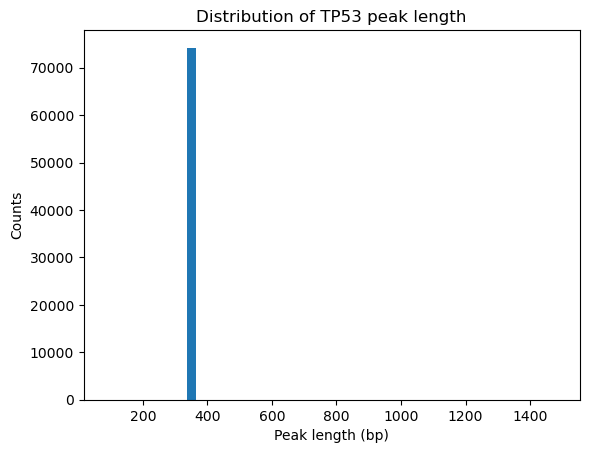

In [8]:
# A. ChiP-seq peaks (BED)
# maps peas to nearest genes using GTF annotations 
# peak densty: count peaks per chromosome 


lengths = [p.length for p in peaks]
import matplotlib.pyplot as plt 
plt.hist(lengths, bins=50)
plt.xlabel("Peak length (bp)")
plt.ylabel("Counts")
plt.title("Distribution of TP53 peak length")
plt.savefig("images/01_peak_length.png", dpi=150, bbox_inches="tight")
plt.show()



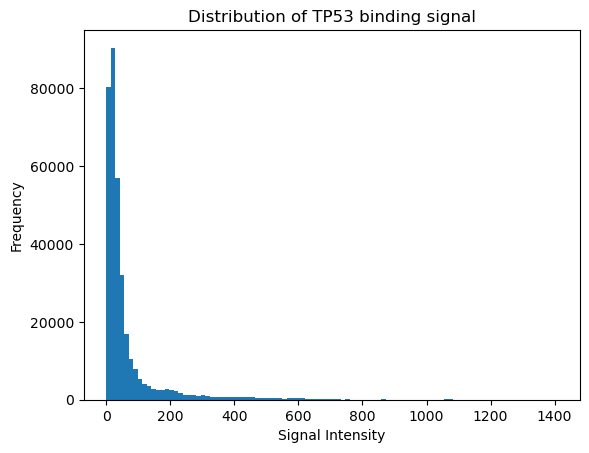

In [9]:
# signal intensity distribution 
# average signal around promoter: plus minus 1kb around transcription start sites (TSS)
bw = pyBigWig.open("GSE176658_ENCFF608GZS_signal_p-value_GRCh38.bigWig")
import numpy as np
vals = []
for p in peaks[:1000]:
    vals.extend(bw.values(p.chrom, p.start, p.end))
        
plt.hist(np.array(vals), bins=100)
plt.xlabel("Signal Intensity")
plt.ylabel("Frequency")
plt.title("Distribution of TP53 binding signal")
plt.savefig("images/02_signal_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

<Axes: >

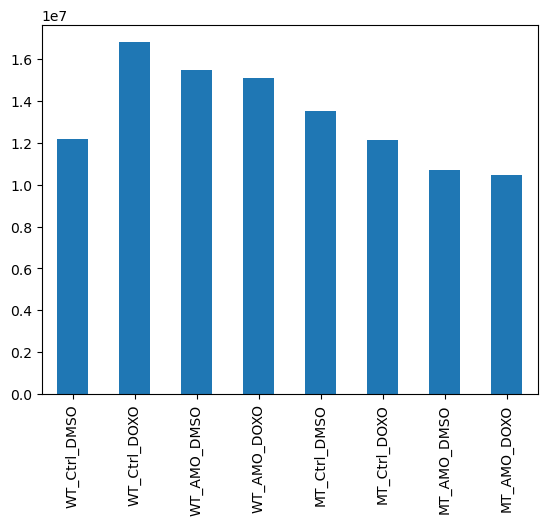

In [10]:
# RNA seq count 
counts.sum(axis=0).plot(kind="bar")

In [11]:
# motif enrichment 
print("Consensus:", tp53_motif.consensus)

Consensus: CCGGACATGCCCGGGCATGT


In [12]:
# Annotate peaks to genes 
# intersect BED peaks with GTF gene annotations 

# INPUT FILES 
BED_FILE = "GSE176658_ENCFF041VRQ_IDR_ranked_peaks_GRCh38.bed"
GTF_FILE = "gencode.v38.annotation.gtf"
OUTPUT_FILE = "TP53_peak_gene_map.tsv"

def annotate_peaks_to_genes(bed_file, gtf_file, output_file):
    peaks = pybedtools.BedTool(bed_file)

    gtf = pybedtools.BedTool(gtf_file)

    genes = gtf.filter(lambda x: x[2] == "gene").saveas()

    closest = peaks.sort().closest(genes.sort(), d=True)

    # write output 
    with open(output_file, "w") as out:
        out.write("peak_chr\tpeak_start\tpeak_end\tgene_id\tgene_name\tdistance\n")
        for entry in closest:
            peak_chr, peak_start, peak_end = entry[0], entry[1], entry[2]

            gene_id, gene_name = "NA", "NA"

            # Attributes are usually second-to-last column before distance
            if len(entry) > 9 and ";" in entry[-2]:
                attrs = {kv.split()[0]: kv.split()[1].strip('"')
                         for kv in entry[-2].split(";")
                         if kv.strip() and len(kv.split()) > 1}
                gene_id = attrs.get("gene_id", "NA")
                gene_name = attrs.get("gene_name", "NA")

            distance = entry[-1]
            out.write(f"{peak_chr}\t{peak_start}\t{peak_end}\t{gene_id}\t{gene_name}\t{distance}\n")
            
    print(f"[INFO] Annotation complete. Results saved to {output_file}")

if __name__ == "__main__":
    annotate_peaks_to_genes(BED_FILE, GTF_FILE, OUTPUT_FILE)



[INFO] Annotation complete. Results saved to TP53_peak_gene_map.tsv


In [13]:
# ṣummarise BigWig Signal per peak 
# computes average signal intensity from a BigWig file for each ChIP-seq peak
# outputs a tab-delimited file; peak coordinates and mean_signal 

BED_FILE = "GSE176658_ENCFF041VRQ_IDR_ranked_peaks_GRCh38.bed"
BIGWIG_FILE = "GSE176658_ENCFF608GZS_signal_p-value_GRCh38.bigWig"
OUTPUT_FILE = "TP53_peak_signal.tsv"

def summarise_peak_signals(bed_file, bigwig_file, output_file):
    peaks = pybedtools.BedTool(bed_file)
    bw = pyBigWig.open(bigwig_file)

    with open(output_file, "w") as out:
        out.write("peak_chr\tpeak_start\tpeak_end\tmean_signal\n")
        for peak in peaks:
            vals = bw.values(peak.chrom, peak.start, peak.end, numpy=True)
            mean_signal = np.nanmean(vals) if vals is not None else 0 
            out.write(f"{peak.chrom}\t{peak.start}\t{peak.end}\t{mean_signal:.4f}\n")

    bw.close()
    print(f"[INFO] Signal summarization complete. Results saved to {output_file}")

if __name__ == "__main__":
    summarise_peak_signals(BED_FILE, BIGWIG_FILE, OUTPUT_FILE) 

[INFO] Signal summarization complete. Results saved to TP53_peak_signal.tsv


In [14]:
# RNA SEQ COUNT MATRIX ANALYSIS 
import pandas as pd 
COUNT_FILE = "GSE274604_count.txt"

counts = pd.read_csv(COUNT_FILE, sep="\t", index_col = 0)
counts = counts.dropna(axis=1, how="all")
print("[INFO] Raw counts shape:", counts.shape)
print(counts.shape)

# filter genes with total counts < 10 across all samples 
filtered = counts[counts.sum(axis = 1) >= 10]
print("\n[INFO] After filtering: ", filtered.shape)

# normalize counts 
import numpy as np 

# compute geomteric means 
geometric_means = np.exp(np.log(filtered+1).mean(axis=1))

# ratios and size factors 
ratios = filtered.div(geometric_means, axis = 0)
size_factors = ratios.median(axis=0)

# save nornalised counts 
normalized = filtered.div(size_factors, axis=1)
OUTPUT_FILE = "RNAseq_normalized_counts.tsv"
normalized.to_csv(OUTPUT_FILE, sep="\t")
print(f"\n[INFO] Noralized counts saved to {OUTPUT_FILE}")



[INFO] Raw counts shape: (43424, 8)
(43424, 8)

[INFO] After filtering:  (20688, 8)

[INFO] Noralized counts saved to RNAseq_normalized_counts.tsv


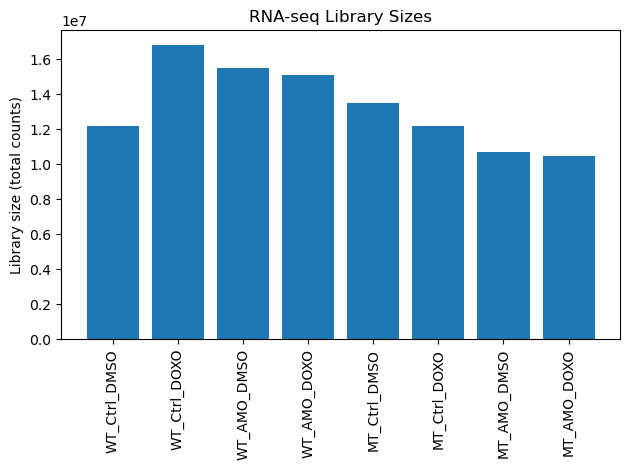

In [15]:
lib_sizes = counts.sum(axis=0)
plt.bar(lib_sizes.index, lib_sizes.values)
plt.xticks(rotation=90)
plt.ylabel("Library size (total counts)")
plt.title("RNA-seq Library Sizes")
plt.tight_layout()
plt.savefig("images/03_library_sizes.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
import sklearn
print(sklearn.__version__)
import numpy as np

1.7.2


(20688, 8)
0
(20688, 8)


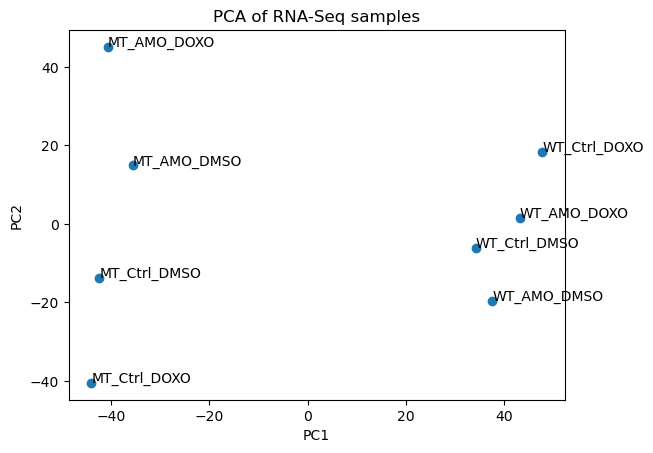

[INFO] PCA coordinates saved to RNAseq_PCA_coordinates.tsv


In [17]:
print(normalized.shape)
print(normalized.isna().sum().sum())   # total NaNs

normalized_clean = normalized.fillna(0)
print(normalized_clean.shape)

normalized_clean = normalized_clean.apply(pd.to_numeric, errors="coerce").fillna(0)

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pcs = pca.fit_transform(np.log1p(normalized_clean.T))

plt.scatter(pcs[:,0], pcs[:,1])
for i, sample in enumerate(normalized_clean.columns):
    plt.text(pcs[i,0], pcs[i,1], sample)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of RNA-Seq samples")
plt.savefig("images/04_pca.png", dpi=150, bbox_inches="tight")
plt.show()

# Save PCA coordinates
pca_df = pd.DataFrame(pcs, index=normalized_clean.columns, columns=["PC1", "PC2"])
pca_df.to_csv("RNAseq_PCA_coordinates.tsv", sep="\t")
print("[INFO] PCA coordinates saved to RNAseq_PCA_coordinates.tsv")


In [18]:
# Check the first 10 lines of the motif file
with open("TP53.meme") as f:
    for i in range(10):
        print(f.readline().strip())


MEME version 4

ALPHABET= ACGT

strands: + -

Background letter frequencies
A 0.25 C 0.25 G 0.25 T 0.25

MOTIF MA0106.3 TP53


In [19]:
! head TP53.meme
!ls fimo_out 
!cat fimo_out/fimo.log

MEME version 4

ALPHABET= ACGT

strands: + -

Background letter frequencies
A 0.25 C 0.25 G 0.25 T 0.25

MOTIF MA0106.3 TP53
best_site.narrowPeak  cisml.xml	 fimo.gff  fimo.html  fimo.tsv	fimo.xml
cat: fimo_out/fimo.log: No such file or directory


In [20]:
import pandas as pd

fimo_results = pd.read_csv("fimo_out/fimo.tsv", sep="\t", comment="#")
significant_hits = fimo_results[fimo_results["p-value"] < 1e-6]
significant_hits.to_csv("TP53_motif_hits.tsv", sep="\t", index=False)
print(f"[INFO] {len(significant_hits)} Significant TP53 motif hits saved to TP53_motif_hits.tsv")

[INFO] 5029 Significant TP53 motif hits saved to TP53_motif_hits.tsv


In [21]:
!wc -l fimo_out/fimo.tsv

53555 fimo_out/fimo.tsv


In [22]:
print(significant_hits.shape)
significant_hits.head(10)


(5029, 10)


,motif_id,motif_alt_id,sequence_name,start,stop,strand,score,p-value,q-value,matched_sequence
0,MA0106.3,TP53,15,62262777,62262794,-,27.5102,1.450000e-10,0.134,GACATGCCCAGGCATGTC
1,MA0106.3,TP53,15,62262777,62262794,-,27.5102,1.450000e-10,0.134,GACATGCCCAGGCATGTC
2,MA0106.3,TP53,8,102236840,102236857,-,27.5102,1.450000e-10,0.134,GACATGCCCAGGCATGTC
3,MA0106.3,TP53,17,39046876,39046893,+,27.4286,1.690000e-10,0.134,AACATGCCCAGGCATGTC
4,MA0106.3,TP53,15,62262777,62262794,+,27.2245,2.250000e-10,0.134,GACATGCCTGGGCATGTC
5,MA0106.3,TP53,15,62262777,62262794,+,27.2245,2.250000e-10,0.134,GACATGCCTGGGCATGTC
6,MA0106.3,TP53,8,102236840,102236857,+,27.2245,2.250000e-10,0.134,GACATGCCTGGGCATGTC
7,MA0106.3,TP53,17,39046876,39046893,-,26.9388,3.170000e-10,0.166,GACATGCCTGGGCATGTT
8,MA0106.3,TP53,4,113561331,113561348,-,25.6939,1.230000e-09,0.536,GGCATGCCCAGGCATGTC
9,MA0106.3,TP53,8,8362977,8362994,-,25.6122,1.360000e-09,0.536,AGCATGCCCAGGCATGTC


In [23]:
# count hits per strand 
print(significant_hits['strand'].value_counts())
print(significant_hits['sequence_name'].value_counts().head(10))


strand
-    2540
+    2489
Name: count, dtype: int64
sequence_name
1     454
3     371
2     349
6     291
4     285
11    278
8     277
7     271
5     243
12    235
Name: count, dtype: int64


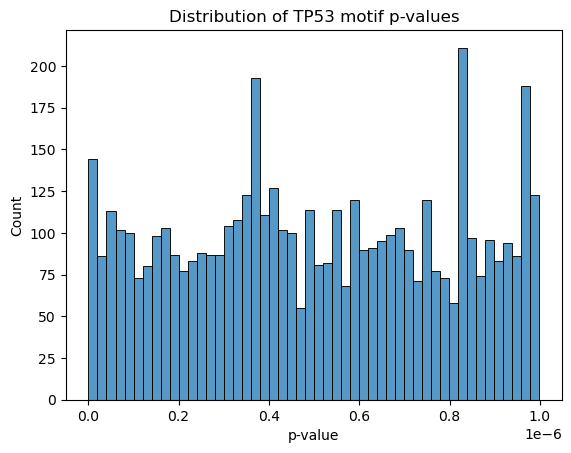

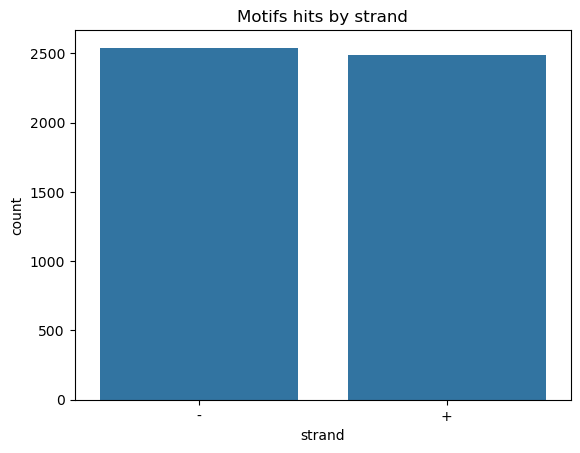

In [24]:
# visualize motif stats 
import matplotlib.pyplot as plt 
import seaborn as sns 

# hist of p values
sns.histplot(significant_hits['p-value'], bins=50)
plt.title("Distribution of TP53 motif p-values")
plt.savefig("images/05_motif_pvalues.png", dpi=150, bbox_inches="tight")
plt.show()

# strand distr
sns.countplot(x='strand', data=significant_hits)
plt.title("Motifs hits by strand")
plt.savefig("images/06_motif_strand.png", dpi=150, bbox_inches="tight")
plt.show()




In [25]:
   print(fimo_results.groupby("sequence_name")["stop"].max().head())

sequence_name
1     248849279
10    133660464
11    135006086
12    133145361
13    114300698
Name: stop, dtype: int64


In [26]:
def to_chr(x):
    x = str(x)
    return x if x.startswith("chr") else ("chrM" if x in ("MT", "M") else "chr" + x)

fimo_results = pd.read_csv("fimo_out/fimo.tsv", sep="\t", comment="#").dropna(subset=["start", "stop"])
fimo_results["chrom"] = fimo_results["sequence_name"].map(to_chr)

# keep only chromosomes that exist in the BigWig (drops scaffolds like GL000194.1)
valid = set(bw.chroms())
n_dropped = (~fimo_results["chrom"].isin(valid)).sum()
fimo_results = fimo_results[fimo_results["chrom"].isin(valid)]
print(f"Dropped {n_dropped} hits on scaffolds not present in the BigWig")

fimo_results[["start", "stop"]] = fimo_results[["start", "stop"]].astype(int)

sites = (fimo_results[fimo_results["p-value"] < 1e-5]
         .sort_values("score", ascending=False)
         .drop_duplicates(["chrom", "start", "stop"]))
print(len(sites), "unique motif sites")

sites_bed = pybedtools.BedTool.from_dataframe(
    sites.assign(bed_start=sites["start"] - 1)[["chrom", "bed_start", "stop", "matched_sequence", "score", "strand"]]
).sort()

Dropped 21 hits on scaffolds not present in the BigWig
23731 unique motif sites


In [27]:
import re
rows = []
with open(GTF_FILE) as fh:
    for line in fh:
        if line.startswith("#"):
            continue
        f = line.rstrip("\n").split("\t")
        if len(f) < 9 or f[2] != "gene":
            continue
        gid = re.search(r'gene_id "([^"]+)"', f[8]).group(1)
        gn = re.search(r'gene_name "([^"]+)"', f[8])
        rows.append((f[0], int(f[3]), int(f[4]), f[6], gid, gn.group(1) if gn else gid))
genes = pd.DataFrame(rows, columns=["chrom", "start", "end", "strand", "gene_id", "gene_name"])
genes["gene_name"] = genes["gene_name"].str.replace('[;"]', "", regex=True).str.strip()
genes["tss"] = np.where(genes["strand"] == "+", genes["start"] - 1, genes["end"] - 1)
genes["p_start"] = (genes["tss"] - 2000).clip(lower=0)
genes["p_end"] = genes["tss"] + 2000
genes["score"] = 0

prom_bed = pybedtools.BedTool.from_dataframe(
    genes[["chrom", "p_start", "p_end", "gene_id", "score", "strand"]]).sort()

pp = peaks.intersect(prom_bed, wa=True, wb=True).to_dataframe(
    names=[f"p{i}" for i in range(20)] + ["g_chrom", "g_start", "g_end", "gene_id", "g_score", "g_strand"])
pp = pp.rename(columns={"p0": "chrom", "p1": "start", "p2": "end", "p6": "signalValue"})
pp = pp.merge(genes[["gene_id", "gene_name"]], on="gene_id")

bound_genes = (pp.groupby("gene_name")
                 .agg(n_peaks=("start", "size"), max_signal=("signalValue", "max"))
                 .reset_index().sort_values("max_signal", ascending=False))
bound_genes.to_csv("TP53_bound_genes.tsv", sep="\t", index=False)
print("Genes with a TP53 peak in the promoter:", len(bound_genes))
bound_genes.head(10)

Genes with a TP53 peak in the promoter: 16415


,gene_name,n_peaks,max_signal
3905,ENSG10010134742.1,6,1110.60869
3937,ENSG10010136441.1,6,1110.60869
3989,ENSG10010139664.1,6,1110.60869
7976,NEAT1,6,1110.60869
7082,MIR21,7,919.85648
3059,CTD-3014M21.1,2,792.85706
15760,WDR74,3,670.17665
10070,RNU2-2P,3,670.17665
10253,RNVU1-22,3,639.97503
10076,RNU4-1,3,522.85524


In [28]:
# check whathappens when we reduce from 2kb to 1 kb 
import re
rows = []
with open(GTF_FILE) as fh:
    for line in fh:
        if line.startswith("#"):
            continue
        f = line.rstrip("\n").split("\t")
        if len(f) < 9 or f[2] != "gene":
            continue
        gid = re.search(r'gene_id "([^"]+)"', f[8]).group(1)
        gn = re.search(r'gene_name "([^"]+)"', f[8])
        rows.append((f[0], int(f[3]), int(f[4]), f[6], gid, gn.group(1) if gn else gid))
genes = pd.DataFrame(rows, columns=["chrom", "start", "end", "strand", "gene_id", "gene_name"])
genes["gene_name"] = genes["gene_name"].str.replace('[;"]', "", regex=True).str.strip()
genes["tss"] = np.where(genes["strand"] == "+", genes["start"] - 1, genes["end"] - 1)
genes["p_start"] = (genes["tss"] - 2000).clip(lower=0)
genes["p_end"] = genes["tss"] + 2000
genes["score"] = 0

prom_bed = pybedtools.BedTool.from_dataframe(
    genes[["chrom", "p_start", "p_end", "gene_id", "score", "strand"]]).sort()

pp = peaks.intersect(prom_bed, wa=True, wb=True).to_dataframe(
    names=[f"p{i}" for i in range(20)] + ["g_chrom", "g_start", "g_end", "gene_id", "g_score", "g_strand"])
pp = pp.rename(columns={"p0": "chrom", "p1": "start", "p2": "end", "p6": "signalValue"})
pp = pp.merge(genes[["gene_id", "gene_name"]], on="gene_id")

bound_genes = (pp.groupby("gene_name")
                 .agg(n_peaks=("start", "size"), max_signal=("signalValue", "max"))
                 .reset_index().sort_values("max_signal", ascending=False))
bound_genes.to_csv("TP53_bound_genes.tsv", sep="\t", index=False)
print("Genes with a TP53 peak in the promoter:", len(bound_genes))

Genes with a TP53 peak in the promoter: 16415


In [29]:
print(sorted(sites["chrom"].unique()))
print(sites.groupby("chrom")["stop"].max().head())

['chr1', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr2', 'chr20', 'chr21', 'chr22', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chrX', 'chrY']
chrom
chr1     248849279
chr10    133660464
chr11    134484376
chr12    133145361
chr13    114300698
Name: stop, dtype: int64


In [ ]:
scanned = sorted(set(sites["chrom"]))

# the DNA that FIMO actually scanned (gene + 1 kb upstream, merged), made in the terminal
scan_df = pd.read_csv("scanned_regions.bed", sep="\t", header=None, names=["chrom", "start", "end"])
scan_df["chrom"] = scan_df["chrom"].map(to_chr)
scan_df = scan_df[scan_df["chrom"].isin(scanned)]
scan_bed = pybedtools.BedTool.from_dataframe(scan_df).sort()
print("scanned DNA on these chromosomes:", f"{(scan_df['end'] - scan_df['start']).sum():,}", "bases")

peaks_bed5 = pybedtools.BedTool.from_dataframe(
    peaks.to_dataframe(usecols=[0, 1, 2, 6], names=["chrom", "start", "end", "signal"])
    .assign(name="peak")[["chrom", "start", "end", "name", "signal"]])

chrom_sizes = bw.chroms()
with open("scanned.genome", "w") as fh:
    for c in scanned:
        fh.write(f"{c}\t{chrom_sizes[c]}\n")

pk_all = peaks_bed5.filter(lambda x: x.chrom in scanned).saveas()
pk = pk_all.intersect(scan_bed, f=1.0, u=True).saveas()      # only peaks fully inside scanned DNA
print(len(pk_all), "peaks on scanned chromosomes ->", len(pk), "fully inside scanned regions")

observed = len(pk.intersect(sites_bed, u=True)) / len(pk)
shuffled = np.array([len(pk.shuffle(g="scanned.genome", chrom=True, incl=scan_bed.fn, seed=s)
                         .intersect(sites_bed, u=True)) / len(pk) for s in range(100)])
print(f"Peaks containing a motif: {observed:.2%} | random regions: {shuffled.mean():.2%} "
      f"| fold = {observed / shuffled.mean():.1f}x | empirical p = {(1 + (shuffled >= observed).sum()) / 101:.3f}")

pd.DataFrame([{"peaks_on_scanned_chromosomes": len(pk_all), "peaks_inside_scanned_regions": len(pk),
               "fraction_with_motif": observed, "fraction_shuffled_mean": shuffled.mean(),
               "fold_enrichment": observed / shuffled.mean(),
               "empirical_p": (1 + (shuffled >= observed).sum()) / 101}]).to_csv("results/motif_in_peaks_all.csv", index=False)

scanned DNA on these chromosomes: 1,807,740,716 bases
74304 peaks on scanned chromosomes -> 57451 fully inside scanned regions


In [ ]:
pk_df = pk.to_dataframe(names=["chrom", "start", "end", "name", "signal"]).sort_values("signal", ascending=False)
strength_rows = []
for n in [1000, 5000, 20000, len(pk_df)]:
    top = pybedtools.BedTool.from_dataframe(pk_df.head(n)).sort()
    obs = len(top.intersect(sites_bed, u=True)) / n
    rnd = np.mean([len(top.shuffle(g="scanned.genome", chrom=True, incl=scan_bed.fn, seed=s)
                       .intersect(sites_bed, u=True)) / n for s in range(20)])
    print(f"top {n:>6} peaks: {obs:.2%} contain a motif vs {rnd:.2%} random ({obs/rnd:.1f}x)")
    strength_rows.append({"top_peaks": n, "fraction_with_motif": obs,
                          "fraction_shuffled": rnd, "fold_enrichment": obs / rnd})
strength_df = pd.DataFrame(strength_rows)
strength_df.to_csv("results/motif_enrichment_by_peak_strength.csv", index=False)

plt.bar([str(n) for n in strength_df["top_peaks"]], strength_df["fold_enrichment"])
plt.xlabel("Top N peaks (ranked by signal)")
plt.ylabel("Fold enrichment of TP53 motif vs shuffled")
plt.title("Motif enrichment vs peak strength (scanned DNA only)")
plt.savefig("images/08_motif_enrichment_by_strength.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
from scipy import stats
log2norm = np.log2(normalized + 1)
lfc = pd.DataFrame({
    "WT_Ctrl": log2norm["WT_Ctrl_DOXO"] - log2norm["WT_Ctrl_DMSO"],
    "WT_AMO":  log2norm["WT_AMO_DOXO"]  - log2norm["WT_AMO_DMSO"],
    "MT_Ctrl": log2norm["MT_Ctrl_DOXO"] - log2norm["MT_Ctrl_DMSO"],
    "MT_AMO":  log2norm["MT_AMO_DOXO"]  - log2norm["MT_AMO_DMSO"],
})
lfc["bound"] = lfc.index.isin(set(bound_genes["gene_name"]))

bu_rows = []
for cond in ["WT_Ctrl", "WT_AMO", "MT_Ctrl", "MT_AMO"]:
    b, u = lfc.loc[lfc["bound"], cond], lfc.loc[~lfc["bound"], cond]
    p = stats.mannwhitneyu(b, u).pvalue
    print(f"{cond}: median log2FC bound = {b.median():.2f}, unbound = {u.median():.2f}, p = {p:.2g}")
    bu_rows.append({"condition": cond, "n_bound": len(b), "n_unbound": len(u),
                    "median_log2FC_bound": round(b.median(), 3),
                    "median_log2FC_unbound": round(u.median(), 3),
                    "mannwhitney_p": p})                       # NEW
pd.DataFrame(bu_rows).to_csv("results/bound_vs_unbound_tests.csv", index=False)   # NEW
lfc.to_csv("results/log2FC_DOXO_vs_DMSO_all_genes.csv")

sns.boxplot(data=lfc.melt(id_vars="bound", var_name="condition", value_name="log2FC"),
            x="condition", y="log2FC", hue="bound", showfliers=False)
plt.title("DOXO vs DMSO: TP53-bound vs unbound promoters")
plt.savefig("images/07_bound_vs_unbound_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
from scipy import stats
print("fraction of expressed genes labelled bound:", round(lfc["bound"].mean(), 3))
sig = peaks.to_dataframe(usecols=[6], names=["s"])["s"]
odds_rows = []
for TOP in [2000, 5000]:
    thr = sig.nlargest(TOP).min()
    strong = set(pp.loc[pp["signalValue"] >= thr, "gene_name"])
    lfc["strong_bound"] = lfc.index.isin(strong)
    for cond in ["WT_Ctrl", "WT_AMO", "MT_Ctrl", "MT_AMO"]:
        ind = lfc[cond] >= 1
        sb = lfc["strong_bound"]
        table = [[(ind & sb).sum(), (~ind & sb).sum()], [(ind & ~sb).sum(), (~ind & ~sb).sum()]]
        odds, p = stats.fisher_exact(table)
        print(f"top {TOP} peaks | {cond}: induced {table[0][0]}/{sb.sum()} bound vs {table[1][0]}/{(~sb).sum()} unbound | OR={odds:.1f}, p={p:.2g}")
        odds_rows.append({"top_peaks": TOP, "condition": cond,
                          "induced_bound": int(table[0][0]), "n_bound": int(sb.sum()),
                          "induced_unbound": int(table[1][0]), "n_unbound": int((~sb).sum()),
                          "odds_ratio": odds, "p_value": p})     
pd.DataFrame(odds_rows).to_csv("results/strong_binding_vs_induction.csv", index=False)   

In [ ]:
import gseapy as gp
induced = [g for g in lfc.index[(lfc["bound"]) & (lfc["WT_Ctrl"] >= 1)]]
induced = sorted(set(pd.Series(induced).str.replace('[;"]', "", regex=True)))
print(len(induced), "TP53-bound genes induced in WT_Ctrl")

enr = gp.enrichr(gene_list=induced,
                 gene_sets=["MSigDB_Hallmark_2020", "KEGG_2021_Human", "GO_Biological_Process_2023"],
                 organism="human", outdir=None)
print(enr.results.sort_values("Adjusted P-value")[["Gene_set", "Term", "Adjusted P-value"]].head(10))
enr.results.sort_values("Adjusted P-value").to_csv("results/enrichr_bound_induced_WT_Ctrl.csv", index=False)

In [ ]:
top_terms = enr.results.sort_values("Adjusted P-value").head(8).iloc[::-1]
plt.figure(figsize=(8, 4))
plt.barh(top_terms["Term"], -np.log10(top_terms["Adjusted P-value"]))
plt.xlabel("-log10 adjusted p-value")
plt.title("Top enriched terms: TP53-bound genes induced in WT_Ctrl")
plt.savefig("images/10_enrichment_top_terms.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
lfc["mean_expr"] = normalized[["WT_Ctrl_DMSO","WT_AMO_DMSO","MT_Ctrl_DMSO","MT_AMO_DMSO"]].mean(axis=1).reindex(lfc.index)
med_expr = lfc.groupby("strong_bound")["mean_expr"].median().round(1)
print(med_expr)
med_expr.to_csv("results/median_expression_bound_vs_unbound.csv") 

ctrl_rows=[]
for MIN in [50, 200]:
    sub = lfc[lfc["mean_expr"] >= MIN]
    sb = sub["strong_bound"]
    for cond in ["WT_Ctrl", "WT_AMO", "MT_Ctrl", "MT_AMO"]:
        ind = sub[cond] >= 1
        table = [[(ind & sb).sum(), (~ind & sb).sum()], [(ind & ~sb).sum(), (~ind & ~sb).sum()]]
        odds, p = stats.fisher_exact(table)
        print(f"expr>={MIN} | {cond}: induced {table[0][0]}/{sb.sum()} bound vs {table[1][0]}/{(~sb).sum()} unbound | OR={odds:.2f}, p={p:.2g}")
        ctrl_rows.append({"min_expression": MIN, "condition": cond,
                          "induced_bound": int(table[0][0]), "n_bound": int(sb.sum()),
                          "induced_unbound": int(table[1][0]), "n_unbound": int((~sb).sum()),
                          "odds_ratio": odds, "p_value": p})     
pd.DataFrame(ctrl_rows).to_csv("results/expression_controlled_tests.csv", index=False)  

In [ ]:
known = ["CDKN1A","MDM2","BAX","GADD45A","BBC3","PMAIP1","TP53INP1","SESN1","ZMAT3","DDB2","FAS","TNFRSF10B"]
known_tbl = lfc.loc[lfc.index.isin(known), ["WT_Ctrl","WT_AMO","MT_Ctrl","MT_AMO","bound","strong_bound"]].round(2)
known_tbl.to_csv("results/known_p53_targets.csv")                        # NEW
known_tbl

In [ ]:
plt.figure(figsize=(5.5, 5))
sns.heatmap(known_tbl[["WT_Ctrl","WT_AMO","MT_Ctrl","MT_AMO"]], annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Known p53 targets: log2FC (DOXO vs DMSO)")
plt.savefig("images/09_known_targets_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()